In [1]:
import sys
sys.path.append("..")

In [3]:
from src.image_utils import load_image, save_image

tensor = load_image("../data/content/Abyssinian_24.jpg", 384, "cuda")

In [4]:
tensor.shape

torch.Size([1, 3, 288, 384])

In [8]:
tensor.min(), tensor.max()

(tensor(0., device='cuda:0'), tensor(1., device='cuda:0'))

In [ ]:
tensor.get_device()

0

In [10]:
save_image(tensor, "../outputs/test_save.jpg")

In [2]:
import torch
from src.losses import content_loss

generated = torch.tensor([1., 2., 3., 4.])
target = torch.tensor([2., 2., 2., 2.])

loss = content_loss(generated, target)

In [3]:
loss

tensor(1.5000)

In [4]:
generated = torch.tensor([1., 2., 3., 4.])
target = torch.tensor([1., 2., 3., 4.])

loss = content_loss(generated, target)
loss

tensor(0.)

In [5]:
generated = torch.tensor([1., 2., 3., 4.], requires_grad=True)
target = torch.tensor([2., 2., 2., 2.])

loss = content_loss(generated, target)
loss.backward()

In [6]:
generated.grad

tensor([-0.5000,  0.0000,  0.5000,  1.0000])

In [4]:
import torch
from src.vgg import VGGFeatures
from src.image_utils import load_image
from src.losses import content_loss

device = "cuda"
extractor = VGGFeatures().to(device)

content = load_image("../data/content/Abyssinian_24.jpg", 384, device)
style = load_image("../data/style/starry_night.jpg", 384, device)

with torch.no_grad():
    content_feat = extractor(content)["conv4_2"]
    style_feat = extractor(style)["conv4_2"]

print("content vs content:", content_loss(content_feat, content_feat).item())
print("content feature shape:", tuple(content_feat.shape))
print("style feature shape:", tuple(style_feat.shape))

content vs content: 0.0
content feature shape: (1, 512, 36, 48)
style feature shape: (1, 512, 38, 48)


In [1]:
import sys
sys.path.append("..")

import torch
import torch.nn.functional as F
from src.vgg import VGGFeatures
from src.image_utils import load_image
from src.losses import content_loss

device = "cuda"
extractor = VGGFeatures().to(device)

content = load_image("../data/content/Abyssinian_24.jpg", 384, device)
style = load_image("../data/style/starry_night.jpg", 384, device)

# Test only: force the style image to the content image's height and width
style = F.interpolate(style, size=content.shape[-2:], mode="bilinear", align_corners=False)

print("content:", content.shape, "| style:", style.shape)

with torch.no_grad():
    content_feat = extractor(content)["conv4_2"]
    style_feat = extractor(style)["conv4_2"]

print("content vs content:", content_loss(content_feat, content_feat).item())
print("content vs style:  ", content_loss(content_feat, style_feat).item())

content: torch.Size([1, 3, 288, 384]) | style: torch.Size([1, 3, 288, 384])
content vs content: 0.0
content vs style:   162.31199645996094


In [7]:
with torch.no_grad():
    target = extractor(content)["conv4_2"]
print(target.shape)

torch.Size([1, 512, 36, 48])


In [8]:
image = torch.rand_like(content, requires_grad= True)

In [9]:
optimiser = torch.optim.Adam([image], lr=0.02)

In [10]:
for i in range(1,601):
    optimiser.zero_grad()
    features = extractor(image)["conv4_2"]
    loss = content_loss(features, target)
    loss.backward()
    optimiser.step()
    with torch.no_grad():
        image.clamp_(0,1)
    if i % 100 == 0:
        print(f"Iteration {i}: loss={loss.item():.4f}")
    

Iteration 100: loss=3.0811
Iteration 200: loss=1.5322
Iteration 300: loss=1.0354
Iteration 400: loss=0.7943
Iteration 500: loss=0.6490
Iteration 600: loss=0.5595


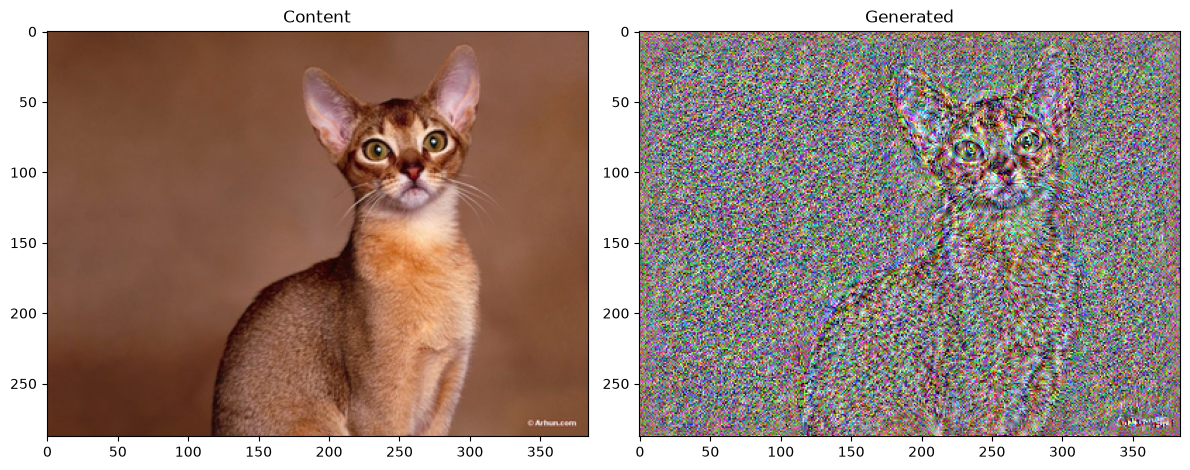

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].set_title("Content")
ax[0].imshow(content.detach().cpu().squeeze(0).permute(1,2,0).numpy())
ax[1].set_title("Generated")
ax[1].imshow(image.detach().cpu().squeeze(0).permute(1,2,0).numpy())
fig.tight_layout()
fig.savefig("../outputs/content_reconstruction.jpg")